# RQ4: Families

This notebook compares how the model families evolved across their releases, and whether they follow the same path.

The process consists of:
1. **Releases per Family**: Counting the releases and the model runs of each family in each size category.
2. **Trajectories**: Following the instruct releases of each family in the plane of accuracy and energy per question.
3. **First to Last Release**: Splitting the change of intelligence efficiency of each trajectory into its three factors.
4. **Families Side by Side**: Comparing the families that released a model in the same year and size category.
5. **Family Effects**: Estimating the difference between families at equal release date and size category.
6. **Key Values**: Printing the main values of this notebook.

### Setup & Imports
We load the tables built by `00-dataset.ipynb` and the chart helpers of `common.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy import stats

from common import (
    CATEGORY_COLORS,
    CATEGORY_ORDER,
    FACTOR_COLORS,
    FAMILY_MARKERS,
    FAMILY_ORDER,
    SCATTER_STYLE,
    category_panels,
    contributions,
    factor_handles,
    legend_handles,
    load_model_runs,
    percent_axis,
    plain_log_axis,
    save_chart,
    short_name,
    stacked_contributions,
    with_log_factors,
)

model_runs = with_log_factors(load_model_runs()).sort_values(["release_date", "model_run"]).reset_index(drop=True)
model_runs["year"] = model_runs["release_date"].dt.year
instruct = model_runs[model_runs["mode"] == "Instruct"]

print(f"Model runs: {len(model_runs)}   instruct: {len(instruct)}   families: {model_runs['family'].nunique()}")

Model runs: 53   instruct: 38   families: 6


### 1. Releases per Family
We count the releases of each family, and its instruct and reasoning runs in each size category. A family can only show a trajectory in a size category where it has instruct runs from more than one release.

In [2]:
releases = model_runs.groupby("family").agg(
    releases=("release", "nunique"),
    first_release=("release_date", "min"),
    last_release=("release_date", "max"),
).reindex(FAMILY_ORDER)
releases["first_release"] = releases["first_release"].dt.date
releases["last_release"] = releases["last_release"].dt.date

counts = model_runs.assign(category=pd.Categorical(model_runs["category"], CATEGORY_ORDER, ordered=True)).pivot_table(index="family", columns=["category", "mode"], values="model_run", aggfunc="count", fill_value=0, observed=False).reindex(FAMILY_ORDER)
counts.columns = [f"{category}, {mode.lower()}" for category, mode in counts.columns]
releases.join(counts)

,releases,first_release,last_release,"Tiny/Mobile, instruct","Tiny/Mobile, reasoning","Small/Edge, instruct","Small/Edge, reasoning","Standard/Desktop, instruct","Standard/Desktop, reasoning"
family,,,,,,,,,
Llama,4,2023-07-13,2024-09-18,1,0,3,0,1,0
Qwen,5,2024-01-30,2026-02-27,5,2,5,2,4,1
Gemma,5,2024-03-26,2026-03-02,4,1,4,1,1,0
DeepSeek,3,2023-11-29,2025-05-29,0,1,1,1,1,1
Phi,2,2024-05-07,2025-04-29,2,1,1,0,2,1
Mistral,1,2025-10-31,2025-10-31,1,1,1,1,1,1


### 2. Trajectories
We follow the instruct runs of each family in the plane of accuracy and GPU energy per question, with one panel per family. In each size category, an arrow joins each release to the next. When a release has more than one instruct model in a size category, the trajectory follows the first one. Reasoning runs are drawn hollow and are not joined, and the runs of the other families are drawn in grey.

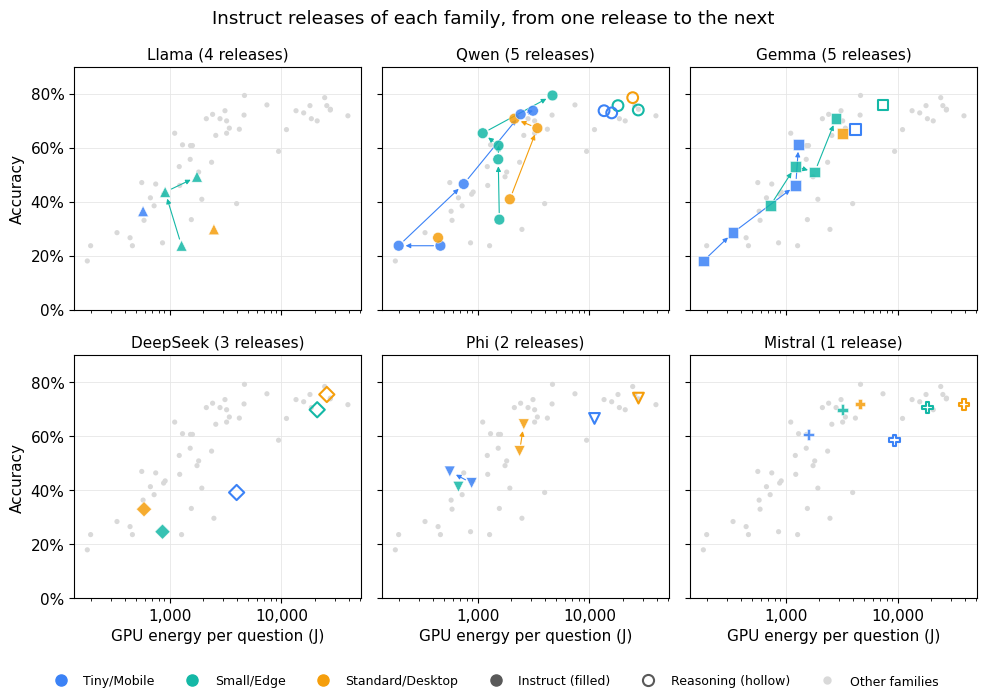

Trajectories with more than one release: 8
  Gemma, Small/Edge: gemma-1.1-7b-it → gemma-2-9b-it → gemma-3n-E4B-it → gemma-4-E4B-it (I)
  Gemma, Tiny/Mobile: gemma-1.1-2b-it → gemma-2-2b-it → gemma-3-4b-it → gemma-4-E2B-it (I)
  Llama, Small/Edge: Llama-2-7b-chat-hf → Meta-Llama-3-8B-Instruct → Llama-3.1-8B-Instruct
  Phi, Standard/Desktop: Phi-3-medium-4k-instruct → phi-4
  Phi, Tiny/Mobile: Phi-3.5-mini-instruct → Phi-4-mini-instruct
  Qwen, Small/Edge: Qwen1.5-7B-Chat → Qwen2-7B-Instruct → Qwen2.5-7B-Instruct → Qwen3-8B (I) → Qwen3.5-9B (I)
  Qwen, Standard/Desktop: Qwen1.5-14B-Chat → Qwen2.5-14B-Instruct → Qwen3-14B (I)
  Qwen, Tiny/Mobile: Qwen1.5-4B-Chat → Qwen2-1.5B-Instruct → Qwen2.5-3B-Instruct → Qwen3-4B-Instruct-2507 → Qwen3.5-4B (I)


In [3]:
# One instruct run per family, size category and release
trajectory_runs = instruct.drop_duplicates(["family", "category", "release"], keep="first")
trajectories = {key: runs for key, runs in trajectory_runs.groupby(["family", "category"]) if len(runs) > 1}

fig, axes = plt.subplots(2, 3, figsize=(10, 7), sharex=True, sharey=True)
for ax, family in zip(axes.flat, FAMILY_ORDER):
    others = model_runs[model_runs["family"] != family]
    ax.scatter(others["gpu_joules_per_question"], others["accuracy"], s=14, color="0.85", edgecolors="none", zorder=1)
    runs = model_runs[model_runs["family"] == family]
    for mode, group in runs.groupby("mode"):
        colors = group["category"].map(CATEGORY_COLORS)
        if mode == "Instruct":
            ax.scatter(group["gpu_joules_per_question"], group["accuracy"], c=colors, marker=FAMILY_MARKERS[family], edgecolors="w", zorder=3, **SCATTER_STYLE)
        else:
            ax.scatter(group["gpu_joules_per_question"], group["accuracy"], facecolors="none", edgecolors=colors, marker=FAMILY_MARKERS[family], s=60, linewidth=1.5, zorder=3)
    for (trajectory_family, category), steps in trajectories.items():
        if trajectory_family == family:
            for (_, start), (_, end) in zip(steps.iloc[:-1].iterrows(), steps.iloc[1:].iterrows()):
                ax.annotate(
                    "",
                    xy=(end["gpu_joules_per_question"], end["accuracy"]),
                    xytext=(start["gpu_joules_per_question"], start["accuracy"]),
                    arrowprops=dict(arrowstyle="-|>", color=CATEGORY_COLORS[category], linewidth=0.8, mutation_scale=7, shrinkA=5, shrinkB=5),
                    zorder=2,
                )
    ax.set_xscale("log")
    plain_log_axis(ax.xaxis, subs=(1,))
    ax.set_ylim(0, 0.9)
    percent_axis(ax.yaxis)
    ax.set_title(f"{family} ({runs['release'].nunique()} release{'s' if runs['release'].nunique() > 1 else ''})", fontsize=11)
for ax in axes[-1]:
    ax.set_xlabel("GPU energy per question (J)")
for ax in axes[:, 0]:
    ax.set_ylabel("Accuracy")
handles = legend_handles()
handles.append(Line2D([], [], marker="o", linestyle="", markersize=5, color="0.85", label="Other families"))
fig.legend(handles=handles, loc="lower center", ncol=6, fontsize=9, frameon=False)
fig.suptitle("Instruct releases of each family, from one release to the next")
plt.tight_layout(rect=(0, 0.05, 1, 1))
save_chart(fig, "rq4-trajectories")
plt.show()

print(f"Trajectories with more than one release: {len(trajectories)}")
for (family, category), steps in trajectories.items():
    print(f"  {family}, {category}: " + " → ".join(steps["model_run"].map(short_name)))

### 3. First to Last Release
We split the change of intelligence efficiency between the first and the last release of each trajectory into the contributions of its three factors: accuracy, response length and energy per token. The table gives each contribution as a factor (above 1 improves the intelligence efficiency), with the change of accuracy and of GPU energy per question.

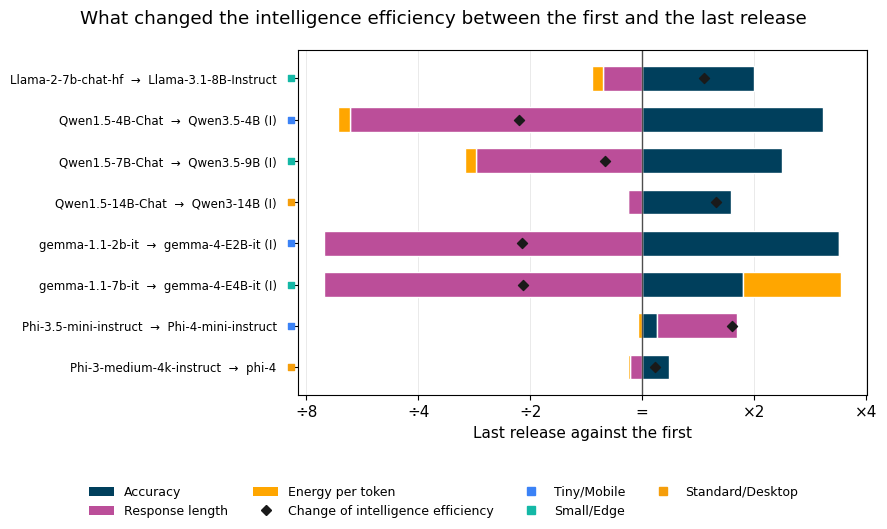

from                     to  \
family category                                                            
Llama  Small/Edge              Llama-2-7b-chat-hf  Llama-3.1-8B-Instruct   
Qwen   Tiny/Mobile                Qwen1.5-4B-Chat         Qwen3.5-4B (I)   
       Small/Edge                 Qwen1.5-7B-Chat         Qwen3.5-9B (I)   
       Standard/Desktop          Qwen1.5-14B-Chat          Qwen3-14B (I)   
Gemma  Tiny/Mobile                gemma-1.1-2b-it     gemma-4-E2B-it (I)   
       Small/Edge                 gemma-1.1-7b-it     gemma-4-E4B-it (I)   
Phi    Tiny/Mobile          Phi-3.5-mini-instruct    Phi-4-mini-instruct   
       Standard/Desktop  Phi-3-medium-4k-instruct                  phi-4   

                         releases  months  Accuracy (points)  \
family category                                                
Llama  Small/Edge               3      12               25.5   
Qwen   Tiny/Mobile              5      25               50.0   
       Small/Edge               5      25               46.0   
       Standard/Desktop         3      15               29.8   
Gemma  Tiny/Mobile              4      23               43.0   
       Small/Edge               4      23               32.3   
Phi    Tiny/Mobile              2       6                4.3   
       Standard/Desktop         2       7                9.9   

                         Energy per question (ratio)  Accuracy  \
family category                                                  
Llama  Small/Edge                               1.37      2.00   
Qwen   Tiny/Mobile                              6.72      3.07   
       Small/Edge                               2.98      2.38   
       Standard/Desktop                         1.10      1.73   
Gemma  Tiny/Mobile                              7.09      3.38   
       Small/Edge                               3.88      1.87   
Phi    Tiny/Mobile                              0.64      1.10   
       Standard/Desktop                         1.09      1.18   

                         Response length  Energy per token   Net  
family category                                                   
Llama  Small/Edge                   0.78              0.94  1.47  
Qwen   Tiny/Mobile                  0.16              0.93  0.47  
       Small/Edge                   0.36              0.94  0.80  
       Standard/Desktop             0.91              1.00  1.58  
Gemma  Tiny/Mobile                  0.14              1.00  0.47  
       Small/Edge                   0.14              1.83  0.48  
Phi    Tiny/Mobile                  1.64              0.97  1.75  
       Standard/Desktop             0.93              0.99  1.08

In [4]:
rows = []
for (family, category), steps in trajectories.items():
    first, last = steps.iloc[0], steps.iloc[-1]
    rows.append({
        "family": family,
        "category": category,
        "from": short_name(first["model_run"]),
        "to": short_name(last["model_run"]),
        "months": round((last["release_date"] - first["release_date"]).days / 30.44),
        "releases": len(steps),
        "accuracy_points": 100 * (last["accuracy"] - first["accuracy"]),
        "energy_per_question_ratio": last["gpu_joules_per_question"] / first["gpu_joules_per_question"],
        **contributions(first, last),
    })
changes = pd.DataFrame(rows)
changes["family"] = pd.Categorical(changes["family"], FAMILY_ORDER, ordered=True)
changes["category"] = pd.Categorical(changes["category"], CATEGORY_ORDER, ordered=True)
changes = changes.sort_values(["family", "category"]).reset_index(drop=True)
assert np.allclose(changes[list(FACTOR_COLORS)].sum(axis=1), changes["Net"])

fig, ax = plt.subplots(figsize=(9, 0.42 * len(changes) + 1.9))
table = changes.iloc[::-1].reset_index(drop=True)
positions = stacked_contributions(ax, table, horizontal=True)
ax.set_yticks(positions, labels=[f"{a}  →  {b}" for a, b in zip(table["from"], table["to"])], fontsize=8.5)
for position, category in zip(positions, table["category"]):
    ax.scatter(-0.012, position, transform=ax.get_yaxis_transform(), marker="s", s=22, color=CATEGORY_COLORS[category], clip_on=False)
ax.tick_params(axis="y", pad=12)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Last release against the first")
fig.suptitle("What changed the intelligence efficiency between the first and the last release")
handles = factor_handles() + [Line2D([], [], marker="s", linestyle="", markersize=6, color=CATEGORY_COLORS[category], label=category) for category in CATEGORY_ORDER]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.13, 1, 1))
save_chart(fig, "rq4-first-to-last-release")
plt.show()

change_table = changes[["family", "category", "from", "to", "releases", "months"]].copy()
change_table["Accuracy (points)"] = changes["accuracy_points"].round(1)
change_table["Energy per question (ratio)"] = changes["energy_per_question_ratio"].round(2)
for factor in list(FACTOR_COLORS) + ["Net"]:
    change_table[factor] = np.exp(changes[factor]).round(2)
change_table.set_index(["family", "category"])

### 4. Families Side by Side
We compare the families that released an instruct model in the same year and size category, using the last release of each family in that year. The vertical line spans the families of each year. The table gives that spread: the difference between the highest and the lowest accuracy, and the ratio between the highest and the lowest value of the other two metrics.

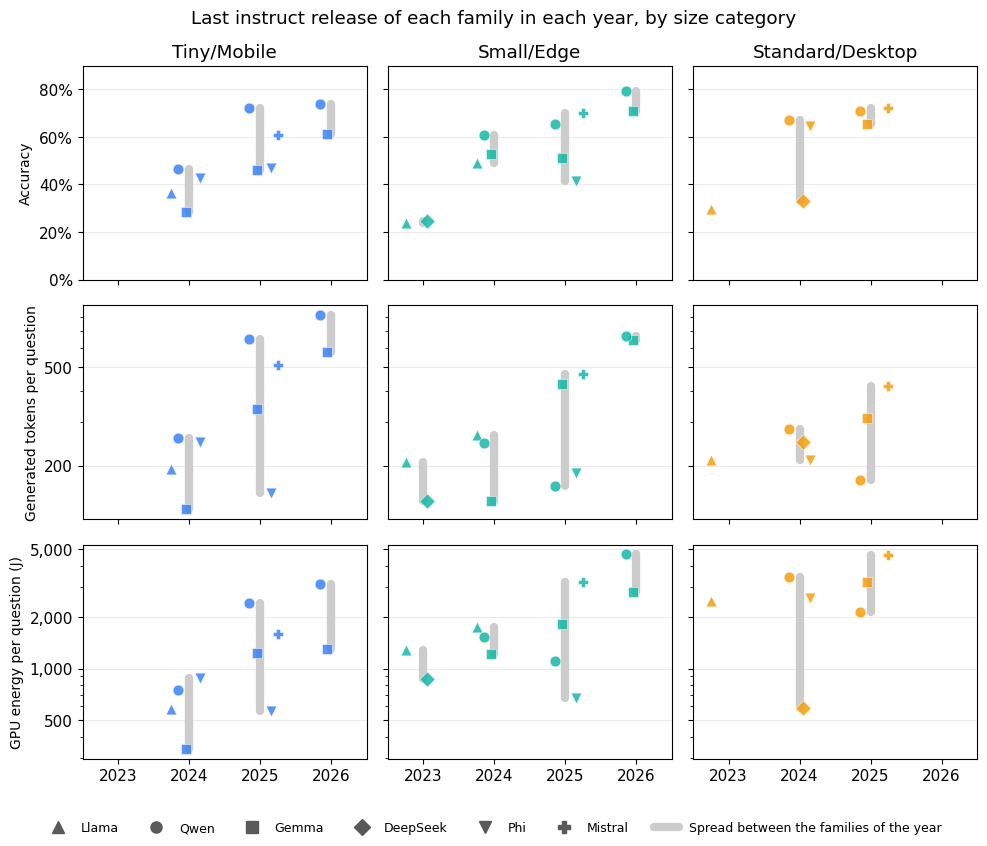

families  accuracy_range_points  tokens_ratio  \
category         year                                                  
Tiny/Mobile      2024         4                   18.0          1.94   
                 2025         4                   26.3          4.20   
                 2026         2                   12.6          1.42   
Small/Edge       2023         2                    1.1          1.43   
                 2024         3                   11.6          1.85   
                 2025         4                   28.5          2.84   
                 2026         2                    8.6          1.04   
Standard/Desktop 2024         3                   34.1          1.34   
                 2025         3                    6.7          2.41   

                       energy_per_question_ratio  
category         year                             
Tiny/Mobile      2024                       2.61  
                 2025                       4.30  
                 2026                       2.40  
Small/Edge       2023                       1.48  
                 2024                       1.44  
                 2025                       4.80  
                 2026                       1.65  
Standard/Desktop 2024                       5.79  
                 2025                       2.17

In [5]:
yearly = trajectory_runs.drop_duplicates(["family", "category", "year"], keep="last")
YEARS = sorted(yearly["year"].unique())
METRICS = {
    "accuracy": "Accuracy",
    "generated_tokens_per_question": "Generated tokens per question",
    "gpu_joules_per_question": "GPU energy per question (J)",
}
# Position of each family around the year, so that the markers do not overlap
OFFSETS = dict(zip(FAMILY_ORDER, np.linspace(-0.25, 0.25, len(FAMILY_ORDER))))

fig, axes = category_panels(nrows=3, figsize=(10, 8.5), sharex=True, sharey="row")
for row, (column, label) in enumerate(METRICS.items()):
    for ax, category in zip(axes[row], CATEGORY_ORDER):
        runs = yearly[yearly["category"] == category]
        for year, group in runs.groupby("year"):
            if len(group) > 1:
                ax.plot([year, year], [group[column].min(), group[column].max()], color="0.8", linewidth=6, solid_capstyle="round", zorder=1)
        for family, group in runs.groupby("family"):
            ax.scatter(group["year"] + OFFSETS[family], group[column], marker=FAMILY_MARKERS[family], color=CATEGORY_COLORS[category], edgecolors="w", zorder=3, **SCATTER_STYLE)
        if column != "accuracy":
            ax.set_yscale("log")
            plain_log_axis(ax.yaxis)
        ax.set_xticks(YEARS)
        ax.set_xlim(YEARS[0] - 0.5, YEARS[-1] + 0.5)
        ax.grid(axis="x", visible=False)
    axes[row][0].set_ylabel(label, fontsize=10)
axes[0][0].set_ylim(0, 0.9)
percent_axis(axes[0][0].yaxis)
families = [family for family in FAMILY_ORDER if family in set(yearly["family"])]
handles = legend_handles(categories=False, families=families, modes=False)
handles.append(Line2D([], [], color="0.8", linewidth=6, solid_capstyle="round", label="Spread between the families of the year"))
fig.legend(handles=handles, loc="lower center", ncol=7, fontsize=9, frameon=False)
fig.suptitle("Last instruct release of each family in each year, by size category")
plt.tight_layout(rect=(0, 0.05, 1, 1))
save_chart(fig, "rq4-families-side-by-side")
plt.show()

spread = yearly.assign(category=pd.Categorical(yearly["category"], CATEGORY_ORDER, ordered=True)).groupby(["category", "year"], observed=True).agg(
    families=("family", "nunique"),
    accuracy_range_points=("accuracy", lambda values: 100 * (values.max() - values.min())),
    tokens_ratio=("generated_tokens_per_question", lambda values: values.max() / values.min()),
    energy_per_question_ratio=("gpu_joules_per_question", lambda values: values.max() / values.min()),
)
spread = spread[spread["families"] > 1]
spread.round({"accuracy_range_points": 1, "tokens_ratio": 2, "energy_per_question_ratio": 2})

### 5. Family Effects
We fit one linear model per metric on the instruct runs, with the release date, the size category and the family as predictors. The effect of a family is its difference from the average of the families at equal release date and size category, with a 95% confidence interval. The F-test compares the model with and without the families. Accuracy is modelled in points, and the other metrics on a log scale, so their effects are factors.

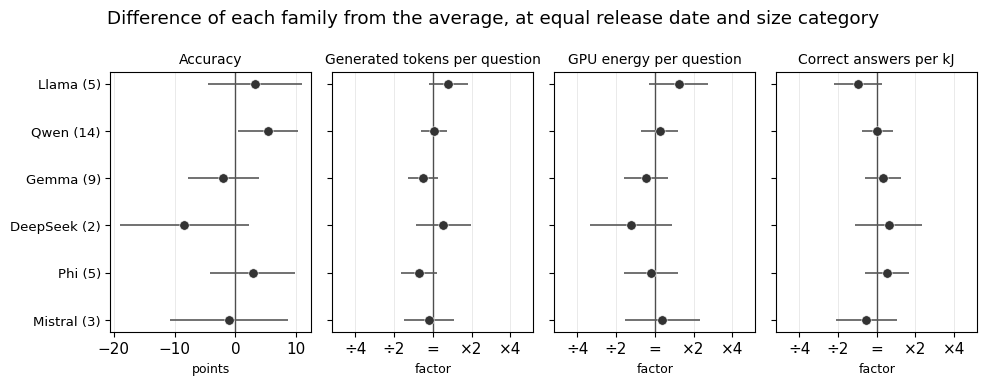

Metric,Accuracy,Generated tokens per question,GPU energy per question,Correct answers per kJ
Per year,+21.2 (+16.6 to +25.8),×2.00 (×1.62 to ×2.47),×1.99 (×1.46 to ×2.72),×0.80 (×0.62 to ×1.04)
Llama,+3.2 (-4.4 to +10.9),×1.32 (×0.93 to ×1.88),×1.53 (×0.91 to ×2.59),×0.71 (×0.46 to ×1.10)
Qwen,+5.4 (+0.5 to +10.3),×1.02 (×0.82 to ×1.28),×1.09 (×0.78 to ×1.53),×1.01 (×0.77 to ×1.33)
Gemma,-2.0 (-7.8 to +3.8),×0.83 (×0.64 to ×1.09),×0.85 (×0.57 to ×1.26),×1.12 (×0.81 to ×1.55)
DeepSeek,-8.4 (-19.1 to +2.2),×1.21 (×0.74 to ×1.97),×0.65 (×0.32 to ×1.35),×1.24 (×0.68 to ×2.24)
Phi,+2.8 (-4.2 to +9.8),×0.79 (×0.57 to ×1.08),×0.93 (×0.58 to ×1.50),×1.21 (×0.82 to ×1.78)
Mistral,-1.1 (-10.8 to +8.6),×0.94 (×0.60 to ×1.46),×1.15 (×0.59 to ×2.23),×0.83 (×0.48 to ×1.43)
F,1.69,1.24,1.06,1.0
p,0.1696,0.3158,0.4004,0.4342
R²,0.83,0.67,0.64,0.48


In [6]:
OUTCOMES = {
    "Accuracy": (100 * instruct["accuracy"], False),
    "Generated tokens per question": (np.log(instruct["generated_tokens_per_question"]), True),
    "GPU energy per question": (np.log(instruct["gpu_joules_per_question"]), True),
    "Correct answers per kJ": (np.log(instruct["correct_answers_per_kj"]), True),
}

years = ((instruct["release_date"] - instruct["release_date"].mean()).dt.days / 365.25).to_numpy()
category_columns = [(instruct["category"] == category).to_numpy(float) for category in CATEGORY_ORDER[1:]]
# Each family is compared with the average of the families: the last one takes -1 in every column
family_columns = [(instruct["family"] == family).to_numpy(float) - (instruct["family"] == FAMILY_ORDER[-1]).to_numpy(float) for family in FAMILY_ORDER[:-1]]
base = np.column_stack([np.ones(len(instruct)), years, *category_columns])
design = np.column_stack([base, *family_columns])
# Rows that turn the coefficients of the model into the effect of each family
to_effects = np.zeros((len(FAMILY_ORDER), design.shape[1]))
to_effects[:-1, base.shape[1]:] = np.eye(len(FAMILY_ORDER) - 1)
to_effects[-1, base.shape[1]:] = -1


def fit_family_effects(values):
    values = values.to_numpy()
    coefficients = np.linalg.lstsq(design, values, rcond=None)[0]
    residuals = values - design @ coefficients
    freedom = len(values) - design.shape[1]
    covariance = (residuals @ residuals / freedom) * np.linalg.inv(design.T @ design)
    margin = stats.t.ppf(0.975, freedom)
    effects = to_effects @ coefficients
    errors = np.sqrt(np.diag(to_effects @ covariance @ to_effects.T))
    # F-test of the model against the one without the families
    reduced = values - base @ np.linalg.lstsq(base, values, rcond=None)[0]
    f_value = ((reduced @ reduced - residuals @ residuals) / len(family_columns)) / (residuals @ residuals / freedom)
    return {
        "effects": effects,
        "low": effects - margin * errors,
        "high": effects + margin * errors,
        "per_year": coefficients[1],
        "per_year_low": coefficients[1] - margin * np.sqrt(covariance[1, 1]),
        "per_year_high": coefficients[1] + margin * np.sqrt(covariance[1, 1]),
        "f_value": f_value,
        "p_value": stats.f.sf(f_value, len(family_columns), freedom),
        "r_squared": 1 - residuals.var() / values.var(),
    }


fits = {name: (fit_family_effects(values), log) for name, (values, log) in OUTCOMES.items()}

positions = np.arange(len(FAMILY_ORDER))[::-1]
fig, axes = plt.subplots(1, 4, figsize=(10, 3.9), sharey=True)
for ax, (name, (fit, log)) in zip(axes, fits.items()):
    ax.axvline(0, color="0.3", linewidth=1)
    ax.hlines(positions, fit["low"], fit["high"], color="0.35", linewidth=1.2, zorder=2)
    ax.scatter(fit["effects"], positions, s=46, color="0.2", edgecolors="w", linewidth=0.4, zorder=3)
    if log:
        ticks = [1 / 4, 1 / 2, 1, 2, 4]
        ax.set_xticks(np.log(ticks), labels=["÷4", "÷2", "=", "×2", "×4"])
        ax.set_xlim(np.log(1 / 6), np.log(6))
        ax.set_xlabel("factor", fontsize=9)
    else:
        ax.set_xlabel("points", fontsize=9)
    ax.set_title(name, fontsize=10)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(positions, labels=[f"{family} ({(instruct['family'] == family).sum()})" for family in FAMILY_ORDER], fontsize=9.5)
fig.suptitle("Difference of each family from the average, at equal release date and size category")
plt.tight_layout()
save_chart(fig, "rq4-family-effects")
plt.show()

rows = []
for name, (fit, log) in fits.items():
    show = (lambda value: f"×{np.exp(value):.2f}") if log else (lambda value: f"{value:+.1f}")
    row = {"Metric": name, "Per year": f"{show(fit['per_year'])} ({show(fit['per_year_low'])} to {show(fit['per_year_high'])})"}
    for family, effect, low, high in zip(FAMILY_ORDER, fit["effects"], fit["low"], fit["high"]):
        row[family] = f"{show(effect)} ({show(low)} to {show(high)})"
    row["F"], row["p"], row["R²"] = round(fit["f_value"], 2), round(fit["p_value"], 4), round(fit["r_squared"], 2)
    rows.append(row)
effects_table = pd.DataFrame(rows).set_index("Metric")
effects_table.T

### 6. Key Values

In [7]:
print("Releases per family:")
print(releases.to_string())

print("\nFirst to last release of each trajectory:")
print(change_table.to_string(index=False))

print("\nSpread between the families of each year:")
print(spread.round({"accuracy_range_points": 1, "tokens_ratio": 2, "energy_per_question_ratio": 2}).to_string())

print("\nFamily effects at equal release date and size category:")
print(effects_table.T.to_string())

Releases per family:
          releases first_release last_release
family                                       
Llama            4    2023-07-13   2024-09-18
Qwen             5    2024-01-30   2026-02-27
Gemma            5    2024-03-26   2026-03-02
DeepSeek         3    2023-11-29   2025-05-29
Phi              2    2024-05-07   2025-04-29
Mistral          1    2025-10-31   2025-10-31

First to last release of each trajectory:
family         category                     from                    to  releases  months  Accuracy (points)  Energy per question (ratio)  Accuracy  Response length  Energy per token  Net
 Llama       Small/Edge       Llama-2-7b-chat-hf Llama-3.1-8B-Instruct         3      12               25.5                         1.37      2.00             0.78              0.94 1.47
  Qwen      Tiny/Mobile          Qwen1.5-4B-Chat        Qwen3.5-4B (I)         5      25               50.0                         6.72      3.07             0.16              0.93 0.47
  Qwen 